## **Importing Required Libraries**

In [2]:
import pathlib
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.preprocessing.image import load_img

## **Defining Training and Testing Dataset Paths**

In [3]:
from pathlib import Path

data_dir_train = Path(r"C:\Users\ADMIN\Desktop\Abhishek\abhishek\Deep Learning\cancer detection\melanoma_cancer_dataset\train")

data_dir_test = Path(r"C:\Users\ADMIN\Desktop\Abhishek\abhishek\Deep Learning\cancer detection\melanoma_cancer_dataset\test")

print(data_dir_train.exists())
print(data_dir_test.exists())

True
True


## **Counting Training and Testing Images**

In [4]:
train_count = sum(
    1 for p in data_dir_train.rglob("*")
    if p.suffix.lower() in [".jpg",".jpg",".png"]
)

test_count = sum(
    1 for p in data_dir_test.rglob("*")
    if p.suffix.lower() in [".jpg",".jpg",".png"]
)

print("Training images:", train_count)
print("Testing images:", test_count)

Training images: 9805
Testing images: 1000


### **Loading Image Dataset and Identifying Classes**

In [5]:
image_dataset = tf.keras.utils.image_dataset_from_directory(
    str(data_dir_train),
    batch_size=32,
    image_size=(180, 180),
    label_mode="categorical",
    seed=123
)

class_names = image_dataset.class_names

print(class_names)

Found 9805 files belonging to 2 classes.
['benign', 'malignant']


### **Visualizing Sample Skin Lesion Images**

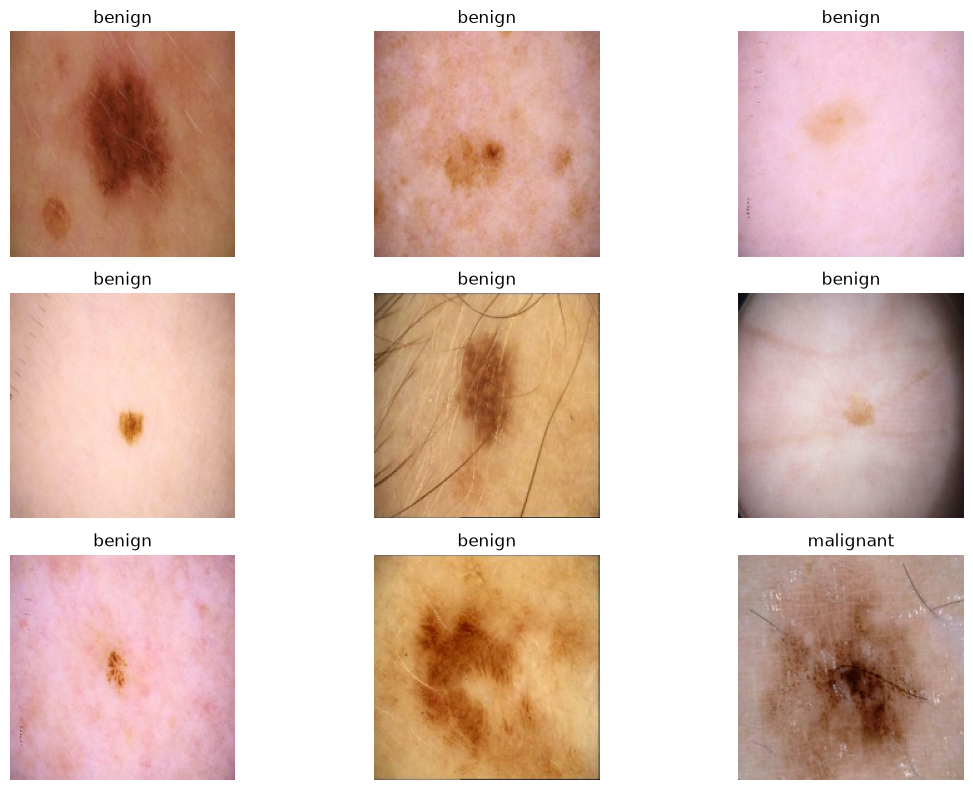

In [6]:
plt.figure(figsize=(12, 8))

for images, labels in image_dataset.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[np.argmax(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

### **Image Augmentation Using Augmentor**

In [7]:
import Augmentor

p = Augmentor.Pipeline(
    str(data_dir_train / class_names[0])
)

p.rotate(probability=0.5, max_left_rotation=10, max_right_rotation=10)
p.flip_left_right(probability=0.5)
p.sample(200)

Initialised with 5000 image(s) found.
Output directory set to C:\Users\ADMIN\Desktop\Abhishek\abhishek\Deep Learning\cancer detection\melanoma_cancer_dataset\train\benign\output.

Processing <PIL.Image.Image image mode=RGB size=300x300 at 0x22358F3DE50>: 100%|██████████| 200/200 [00:00<00:00, 240.84 Samples/s]                  


### **Splitting Dataset into Training and Validation Sets**

In [8]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(data_dir_train),
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(180, 180),
    batch_size=32,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(data_dir_train),
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(180, 180),
    batch_size=32,
    label_mode="categorical"
)

Found 10005 files belonging to 2 classes.
Using 8004 files for training.
Found 10005 files belonging to 2 classes.
Using 2001 files for validation.


### **Optimizing Dataset Performance Using Cache and Prefetch**

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)

### **Building CNN Model Architecture**

In [10]:
model = Sequential()

model.add(layers.Rescaling(
    1./255, input_shape=(180, 180, 3)
))

model.add(layers.Conv2D(
    32, kernel_size=(3, 3), activation="relu"
))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))

model.add(layers.Conv2D(
    64, kernel_size=(3, 3), activation="relu"
))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))

model.add(layers.Conv2D(
    128, kernel_size=(3, 3), activation="relu"
))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))

model.add(layers.Dropout(0.5))
model.add(layers.Flatten())
model.add(layers.Dense(128, activation="relu"))
model.add(layers.Dropout(0.25))
model.add(layers.Dense(len(class_names), activation="softmax"))

model.summary()

C:\Users\ADMIN\anaconda3\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 180, 180, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 178, 178, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 89, 89, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 87, 87, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 43, 43, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 41, 41, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 51200)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       6,553,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │             258 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,647,234 (25.36 MB)

 Trainable params: 6,647,234 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

### **Compiling the CNN Model**

In [11]:
model.compile(
    optimizer="Adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

### **Training the CNN Model with Early Stopping and Model Checkpoint**

In [12]:
checkpoint = ModelCheckpoint(
    "model.h5",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

earlystop = EarlyStopping(
    monitor="val_accuracy",
    patience=5,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[checkpoint, earlystop]
)

Epoch 1/20


C:\Users\ADMIN\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 570ms/step - accuracy: 0.7889 - loss: 0.4534
Epoch 1: val_accuracy improved from None to 0.86007, saving model to model.h5



Epoch 1: finished saving model to model.h5
251/251 ━━━━━━━━━━━━━━━━━━━━ 165s 612ms/step - accuracy: 0.7889 - loss: 0.4534 - val_accuracy: 0.8601 - val_loss: 0.3096
Epoch 2/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 629ms/step - accuracy: 0.8656 - loss: 0.3160
Epoch 2: val_accuracy improved from 0.86007 to 0.87806, saving model to model.h5



Epoch 2: finished saving model to model.h5
251/251 ━━━━━━━━━━━━━━━━━━━━ 166s 661ms/step - accuracy: 0.8656 - loss: 0.3160 - val_accuracy: 0.8781 - val_loss: 0.2731
Epoch 3/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 528ms/step - accuracy: 0.8828 - loss: 0.2785
Epoch 3: val_accuracy did not improve from 0.87806
251/251 ━━━━━━━━━━━━━━━━━━━━ 140s 556ms/step - accuracy: 0.8828 - loss: 0.2785 - val_accuracy: 0.8771 - val_loss: 0.2946
Epoch 4/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 536ms/step - accuracy: 0.8893 - loss: 0.2669
Epoch 4: val_accuracy improved from 0.87806 to 0.88506, saving model to model.h5



Epoch 4: finished saving model to model.h5
251/251 ━━━━━━━━━━━━━━━━━━━━ 142s 566ms/step - accuracy: 0.8893 - loss: 0.2669 - val_accuracy: 0.8851 - val_loss: 0.2581
Epoch 5/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 523ms/step - accuracy: 0.8912 - loss: 0.2564
Epoch 5: val_accuracy improved from 0.88506 to 0.89905, saving model to model.h5


... (3 outputs left out)


Epoch 10: finished saving model to model.h5
251/251 ━━━━━━━━━━━━━━━━━━━━ 141s 560ms/step - accuracy: 0.9083 - loss: 0.2251 - val_accuracy: 0.9075 - val_loss: 0.2241
Epoch 11/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 523ms/step - accuracy: 0.9090 - loss: 0.2200
Epoch 11: val_accuracy improved from 0.90755 to 0.91254, saving model to model.h5



Epoch 11: finished saving model to model.h5
251/251 ━━━━━━━━━━━━━━━━━━━━ 139s 552ms/step - accuracy: 0.9090 - loss: 0.2200 - val_accuracy: 0.9125 - val_loss: 0.2235
Epoch 12/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 528ms/step - accuracy: 0.9105 - loss: 0.2177
Epoch 12: val_accuracy did not improve from 0.91254
251/251 ━━━━━━━━━━━━━━━━━━━━ 140s 556ms/step - accuracy: 0.9105 - loss: 0.2177 - val_accuracy: 0.9040 - val_loss: 0.2293
Epoch 13/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.9180 - loss: 0.2026
Epoch 13: val_accuracy did not improve from 0.91254
251/251 ━━━━━━━━━━━━━━━━━━━━ 137s 547ms/step - accuracy: 0.9180 - loss: 0.2026 - val_accuracy: 0.8991 - val_loss: 0.2387
Epoch 14/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.9153 - loss: 0.2020
Epoch 14: val_accuracy did not improve from 0.91254
251/251 ━━━━━━━━━━━━━━━━━━━━ 139s 554ms/step - accuracy: 0.9153 - loss: 0.2020 - val_accuracy: 0.9000 - val_loss: 0.2403
Epoch 15/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 521m


Epoch 15: finished saving model to model.h5
251/251 ━━━━━━━━━━━━━━━━━━━━ 138s 550ms/step - accuracy: 0.9213 - loss: 0.1935 - val_accuracy: 0.9140 - val_loss: 0.2243
Epoch 16/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 522ms/step - accuracy: 0.9258 - loss: 0.1842
Epoch 16: val_accuracy did not improve from 0.91404
251/251 ━━━━━━━━━━━━━━━━━━━━ 138s 550ms/step - accuracy: 0.9258 - loss: 0.1842 - val_accuracy: 0.9085 - val_loss: 0.2230
Epoch 17/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 522ms/step - accuracy: 0.9267 - loss: 0.1799
Epoch 17: val_accuracy did not improve from 0.91404
251/251 ━━━━━━━━━━━━━━━━━━━━ 138s 550ms/step - accuracy: 0.9267 - loss: 0.1799 - val_accuracy: 0.9090 - val_loss: 0.2322
Epoch 18/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 523ms/step - accuracy: 0.9270 - loss: 0.1820
Epoch 18: val_accuracy did not improve from 0.91404
251/251 ━━━━━━━━━━━━━━━━━━━━ 138s 551ms/step - accuracy: 0.9270 - loss: 0.1820 - val_accuracy: 0.9055 - val_loss: 0.2299
Epoch 19/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 519m


Epoch 19: finished saving model to model.h5
251/251 ━━━━━━━━━━━━━━━━━━━━ 138s 548ms/step - accuracy: 0.9320 - loss: 0.1710 - val_accuracy: 0.9175 - val_loss: 0.2221
Epoch 20/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.9369 - loss: 0.1583
Epoch 20: val_accuracy did not improve from 0.91754
251/251 ━━━━━━━━━━━━━━━━━━━━ 139s 552ms/step - accuracy: 0.9369 - loss: 0.1583 - val_accuracy: 0.8991 - val_loss: 0.2788
Restoring model weights from the end of the best epoch: 19.


### **Visualizing Training and Validation Accuracy**

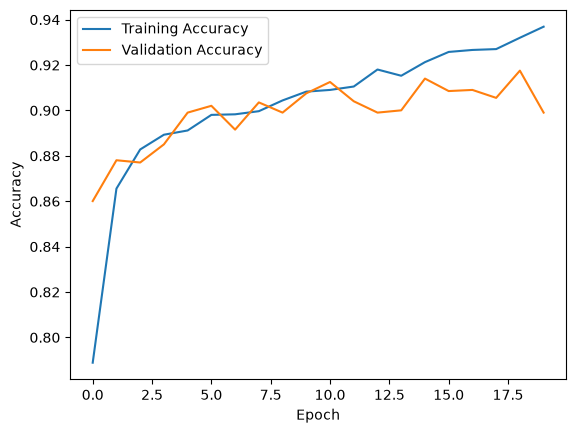

In [13]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### **Saving the Trained CNN Model**

In [14]:
# Save the trained model
model.save("melanoma_model.keras")

print("Model saved successfully!")

Model saved successfully!


### **Loading the Saved CNN Model**

In [15]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "melanoma_model.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


C:\Users\ADMIN\anaconda3\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)


### **Uploading Skin Image and Predicting the Cancer Class**

In [16]:

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from PIL import Image
from IPython.display import display, clear_output

# Upload widget
upload = widgets.FileUpload(
    accept="image/*",
    multiple=False
)

output = widgets.Output()

def predict_image(change):

    with output:
        clear_output(wait=True)

        if not upload.value:
            print("Please upload an image")
            return

        # Get uploaded image
        uploaded_file = upload.value

        if isinstance(uploaded_file, dict):
            image_data = list(uploaded_file.values())[0]["content"]
        else:
            image_data = uploaded_file[0]["content"]

        # Open image
        img = Image.open(
            __import__("io").BytesIO(image_data)
        ).convert("RGB")

        # Display image
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.show()

        # Preprocessing
        img = img.resize((180, 180))

        img_array = np.array(img, dtype=np.float32)
        img_array = np.expand_dims(img_array, axis=0)

        # Prediction
        predictions = model.predict(img_array, verbose=0)

        predicted_index = np.argmax(predictions[0])
        predicted_class = class_names[predicted_index]

        confidence = float(
            predictions[0][predicted_index] * 100
        )

        print("Predicted Class:", predicted_class)
        print("Model Confidence:", round(confidence, 2), "%")

# Button
predict_button = widgets.Button(
    description="Predict",
    button_style="success",
    icon="search"
)

def on_predict_click(b):
    predict_image(None)

predict_button.on_click(on_predict_click)

display(upload)
display(predict_button)
display(output)


FileUpload(value=(), accept='image/*', description='Upload')

Button(button_style='success', description='Predict', icon='search', style=ButtonStyle())

Output()